# Gradient boosting

Histogram gradient-boosted trees (`sklearn.ensemble.HistGradientBoostingRegressor`) on log price. Trees split
on raw values, so they need no scaling and pick up type × area × location interactions on their own, which the
linear baselines need hand-made columns for. Categoricals are handled natively (no one-hot).

**Noise reduction.** One tree model, like one NN, depends on its random seed. With `max_features=0.5` each split
sees a random half of the columns, so models with different `random_state` make different mistakes. The run
averages `BAGS` models of each of two variants (in log space):

- `abs`: absolute-error loss: fits the median, robust to the overpriced / underpriced listings that remain.
- `sq`: squared-error loss with bigger trees (127 leaves).

Both stop early on the **validation split** (the same role val plays in the NN). Settings were picked on
validation MdAPE from a small grid; averaging abs + sq beat each alone.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LAB = Path.cwd()
while not (LAB / "engines").is_dir():  # notebook lives in laboratory/engines/<model>/
    LAB = LAB.parent
sys.path.insert(0, str(LAB))
from engines.common import compare_table, load_config, load_splits, run_seeds

cfg = load_config()  # configs/neural_network_config.yml: same data split, seeds and features as the NN
SEEDS = cfg["data"].get("seeds") or [cfg["data"]["seed"]]
TARGET = cfg["data"]["target"]
FC = cfg["features"]
OUT = LAB / "models" / "gradient_boosting"

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110,
})
print("seeds", SEEDS, "->", OUT)

seeds [42, 7, 13, 21, 99] -> C:\Projects\CADT\property-valuation-model\laboratory\models\gradient_boosting


## Features
Same columns as the NN (`features` in the config), no log / scaling needed:
- **categorical** → integer codes, split natively by the trees. Values seen fewer than 3 times in train, and
  unseen ones, become missing (the trees learn a direction for missing). At most 250 codes per column
  (the sklearn limit is 255); `borey_name` keeps its 250 most common.
- **numeric** and **binary** flags → as is (NaN stays NaN).

In [2]:
MIN_COUNT, MAX_CODES = 3, 250

def cat_values(df, c):
    s = df[c].astype("string").fillna("Unknown").str.strip()
    return df["district"].astype("string").fillna("Unknown").str.strip() + "|" + s if c == "commune" else s

def fit_codes(train):
    """category -> code per column, from train only."""
    codes = {}
    for c in FC["categorical"]:
        vc = cat_values(train, c).value_counts()
        codes[c] = {v: i for i, v in enumerate(vc[vc >= MIN_COUNT].index[:MAX_CODES])}
    return codes

def prep(df, codes):
    x = {c: cat_values(df, c).map(codes[c]).astype(float) for c in FC["categorical"]}
    x |= {c: df[c].astype(float) for c in FC["numeric"] + FC["binary"]}
    return pd.DataFrame(x, index=df.index)

## Model

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor

BAGS = 5
VARIANTS = {
    "abs": dict(loss="absolute_error", learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=10),
    "sq": dict(loss="squared_error", learning_rate=0.03, max_leaf_nodes=127, min_samples_leaf=5),
}
COMMON = dict(l2_regularization=1.0, max_features=0.5, max_iter=4000, early_stopping=True, n_iter_no_change=100)

def fit(train, val, cfg, seed):
    """BAGS models per variant, early-stopped on val. Returns predict(df) -> mean log price."""
    codes = fit_codes(train)
    xt, xv = prep(train, codes), prep(val, codes)
    yt, yv = np.log(train[TARGET]), np.log(val[TARGET])
    is_cat = [c in FC["categorical"] for c in xt.columns]
    models = [HistGradientBoostingRegressor(categorical_features=is_cat, random_state=seed * 100 + b, **v, **COMMON)
              .fit(xt, yt, X_val=xv, y_val=yv)
              for v in VARIANTS.values() for b in range(BAGS)]
    predict = lambda df: np.mean([m.predict(prep(df, codes)) for m in models], axis=0)
    predict.models, predict.codes = models, codes
    return predict

## Train on every seed, score, save
`run_seeds` (in `engines/common.py`) makes the same train/val/test split per seed as the NN, calls `fit`,
scores and writes

```
models/gradient_boosting/ensemble/seed_<s>/metrics.json, test_predictions.csv
models/gradient_boosting/ensemble/summary.json          mean / std over seeds
```

In [4]:
seed_iter = iter(SEEDS)  # run_seeds calls fit once per seed, in order
summary, fitted = run_seeds(lambda tr, va, c: fit(tr, va, c, next(seed_iter)), cfg, OUT / "ensemble")
for s, p in zip(SEEDS, fitted):
    print(f"seed {s}: trees per model {[m.n_iter_ for m in p.models]}")

[seed 42] test MdAPE 21.7%  RMSE log 0.426  R2 0.766


[seed 7] test MdAPE 20.6%  RMSE log 0.407  R2 0.798


[seed 13] test MdAPE 21.6%  RMSE log 0.415  R2 0.759


[seed 21] test MdAPE 20.3%  RMSE log 0.413  R2 0.761


[seed 99] test MdAPE 21.5%  RMSE log 0.416  R2 0.832
seed 42: trees per model [859, 813, 548, 695, 634, 342, 340, 324, 348, 511]
seed 7: trees per model [1477, 1610, 770, 1444, 1472, 447, 365, 407, 373, 347]
seed 13: trees per model [452, 734, 1037, 1238, 963, 281, 350, 438, 290, 288]
seed 21: trees per model [957, 1228, 863, 664, 912, 362, 361, 302, 420, 444]
seed 99: trees per model [630, 611, 532, 506, 423, 270, 271, 325, 295, 363]


### Typical % miss by property type (test MdAPE, mean over seeds)

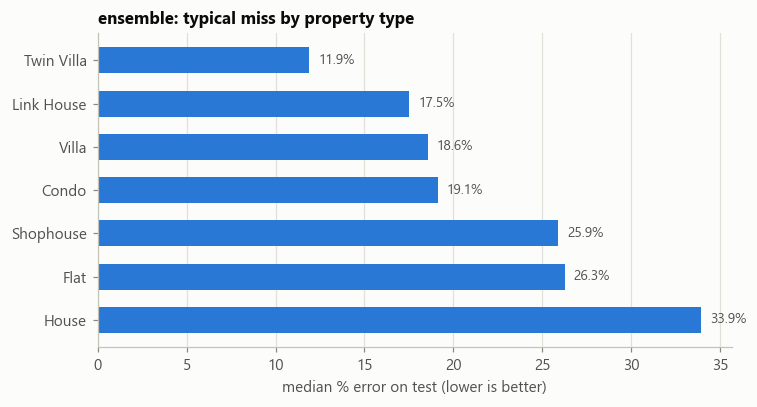

In [6]:
bt = pd.Series({t: m["median_ape"]["mean"] for t, m in summary["test"].items() if t != "overall"}).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.4 * len(bt) + 1))
ax.barh(bt.index, bt, color=SERIES[0], height=0.6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, v in enumerate(bt):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_xlabel("median % error on test (lower is better)")
ax.set_title("ensemble: typical miss by property type")
plt.tight_layout()
plt.show()

## What drives the price
Permutation importance on the first seed's **validation** split: how much val RMSE (log price) grows when one
column is shuffled. Bigger = the model leans on it more. Associations in listing data, not causes.

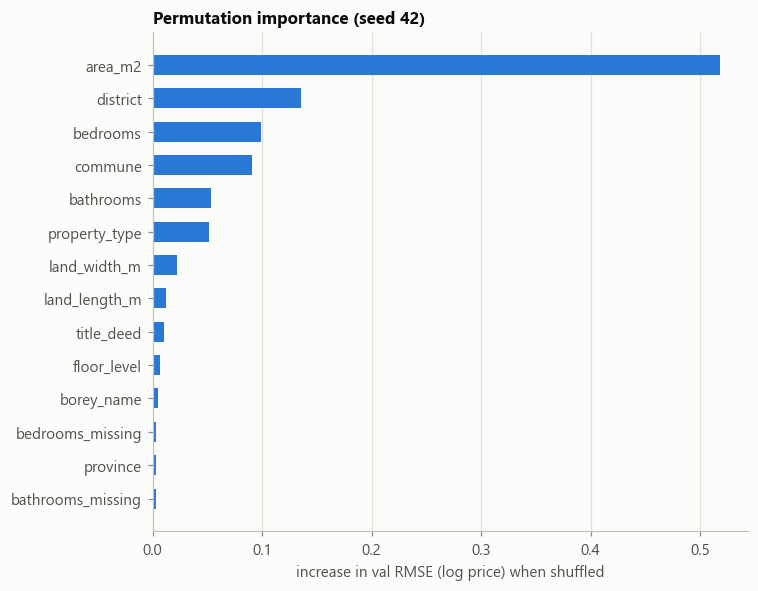

In [7]:
from sklearn.inspection import permutation_importance

_, val0, _ = load_splits(cfg["data"]["path"], cfg["data"]["test_size"], cfg["data"]["val_size"], SEEDS[0])
p0 = fitted[0]
xv0 = prep(val0, p0.codes)

class Ensemble:  # minimal estimator wrapper for permutation_importance
    def fit(self, *a): return self
    def predict(self, x): return np.mean([m.predict(x) for m in p0.models], axis=0)

imp = permutation_importance(Ensemble(), xv0, np.log(val0[TARGET]), scoring="neg_root_mean_squared_error",
                             n_repeats=5, random_state=0)
imp = pd.Series(imp.importances_mean, index=xv0.columns).sort_values()
imp = imp[imp > 0.002]
fig, ax = plt.subplots(figsize=(7, 0.32 * len(imp) + 1))
ax.barh(imp.index, imp, color=SERIES[0], height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("increase in val RMSE (log price) when shuffled")
ax.set_title(f"Permutation importance (seed {SEEDS[0]})")
plt.tight_layout()
plt.show()